In [1]:
import cv2
from fontTools.misc.bezierTools import epsilon
from matplotlib import pyplot as plt
import numpy as np
from numpy.ma.core import transpose

In [2]:
def draw_thick_matches(img1, kp1, img2, kp2, matches, thickness=3):
    h1, w1 = img1.shape[:2]
    h2, w2 = img2.shape[:2]
    out_img = np.zeros((max(h1, h2), w1 + w2, 3), dtype=np.uint8)

    out_img[:h1, :w1, :] = img1
    out_img[:h2, w1:w1+w2, :] = img2

    for m in matches:
        color = tuple(np.random.randint(0, 255, 3).tolist())
        pt1 = (int(kp1[m.queryIdx].pt[0]), int(kp1[m.queryIdx].pt[1]))
        pt2 = (int(kp2[m.trainIdx].pt[0]) + w1, int(kp2[m.trainIdx].pt[1]))

        cv2.line(out_img, pt1, pt2, color, thickness)
        cv2.circle(out_img, pt1, thickness + 1, color, -1)
        cv2.circle(out_img, pt2, thickness + 1, color, -1)

    return out_img

# Then you can just call it natively like this:
# matched_image = draw_thick_matches(prime, prime_keypoints, second, second_keypoints, coherent_matches, thickness=3)

# Match estimation
using sift descriptor we estimate the matches between the two images of the stereo camera.


Pair 1: Found 660 total matches
fundamental_matrix:
[[ 1.12865494e-06 -5.54219315e-06  1.18962654e-03]
 [ 5.36660576e-06 -1.61241541e-06 -3.90545445e-03]
 [-3.80948948e-03  5.58498887e-03  9.99968813e-01]]


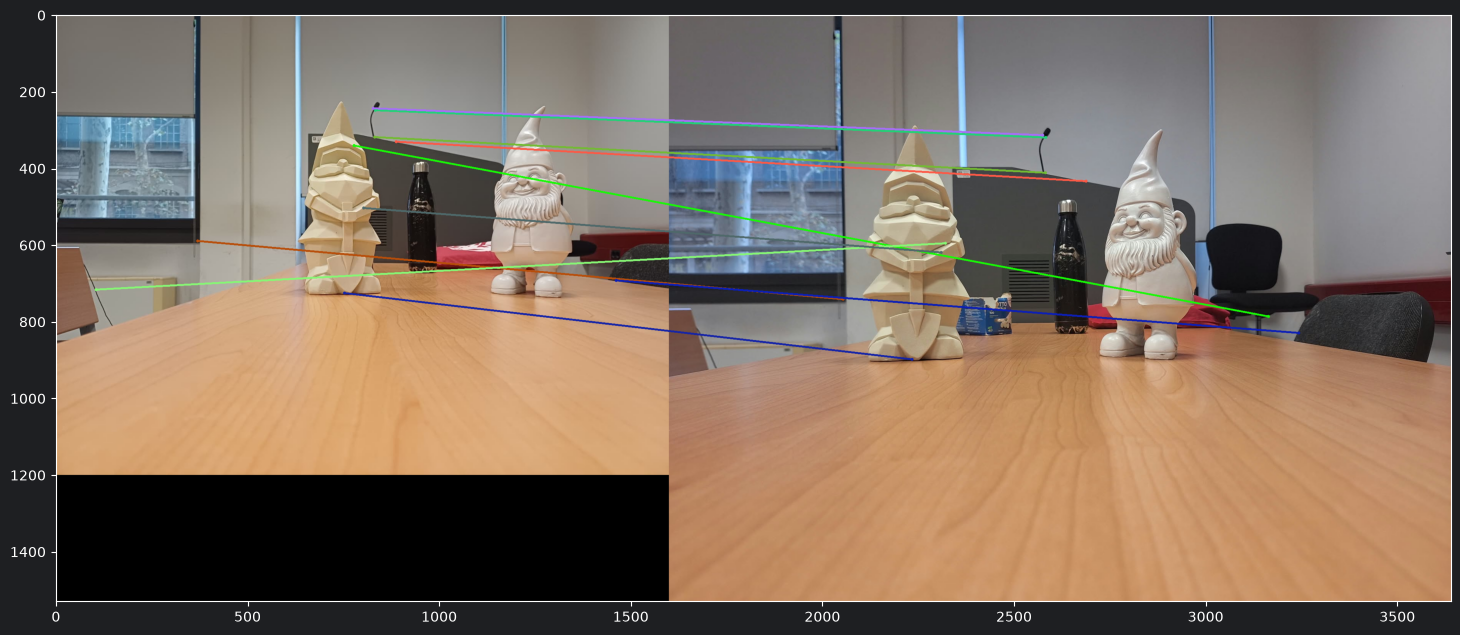

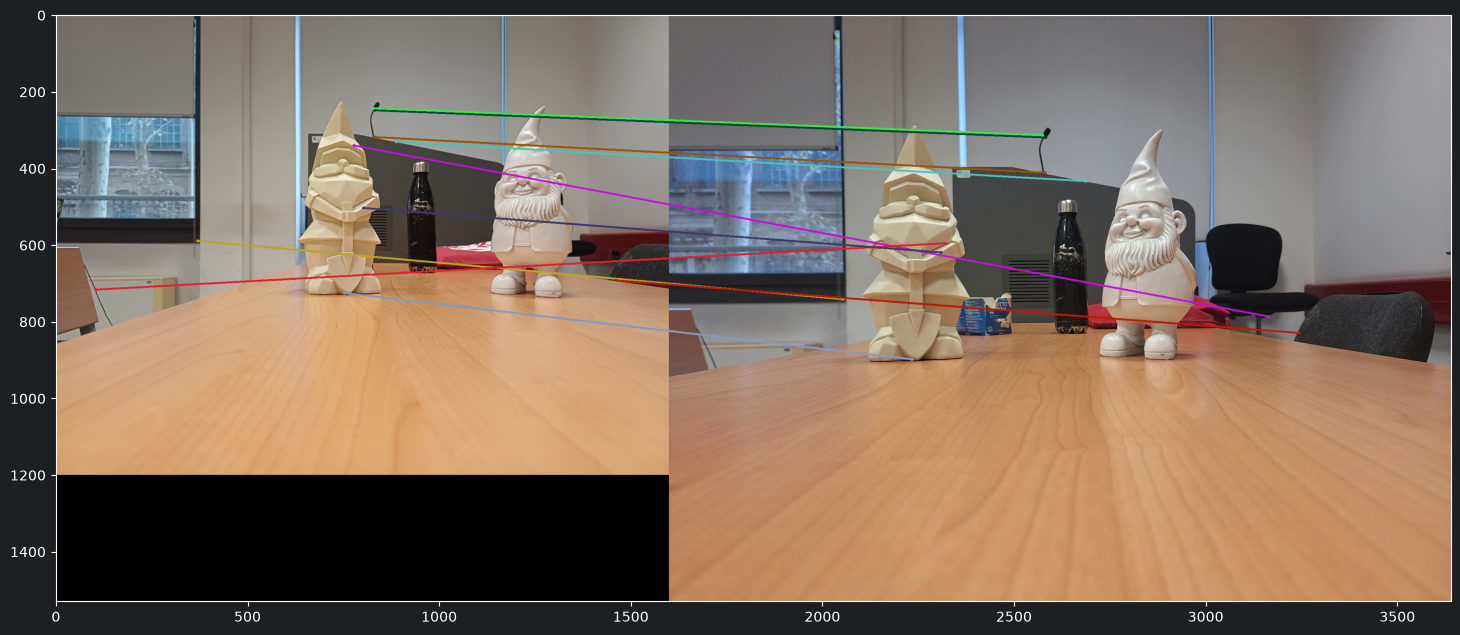

Pair 2: Found 517 total matches
fundamental_matrix:
[[-2.18659345e-06  5.97937802e-06  2.66430255e-05]
 [-3.34267557e-06 -2.68477564e-06  2.47286851e-03]
 [ 2.62441265e-03 -3.24455108e-03 -9.99988235e-01]]


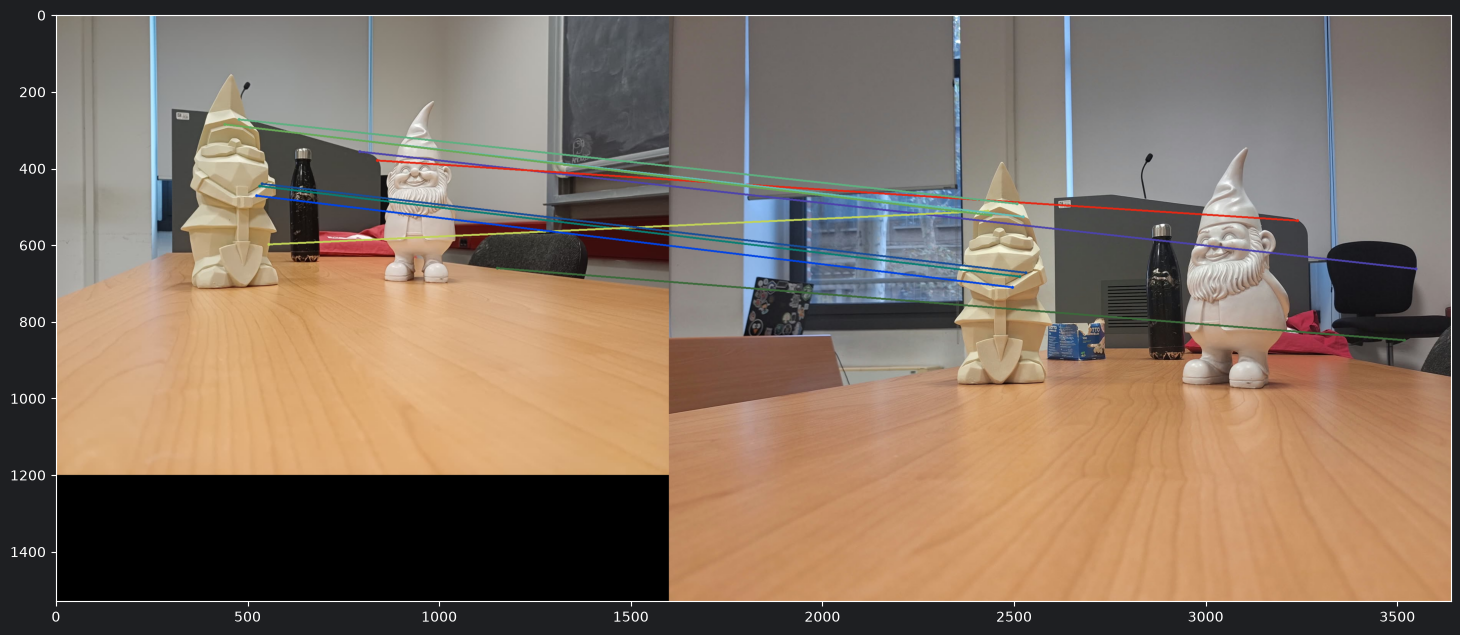

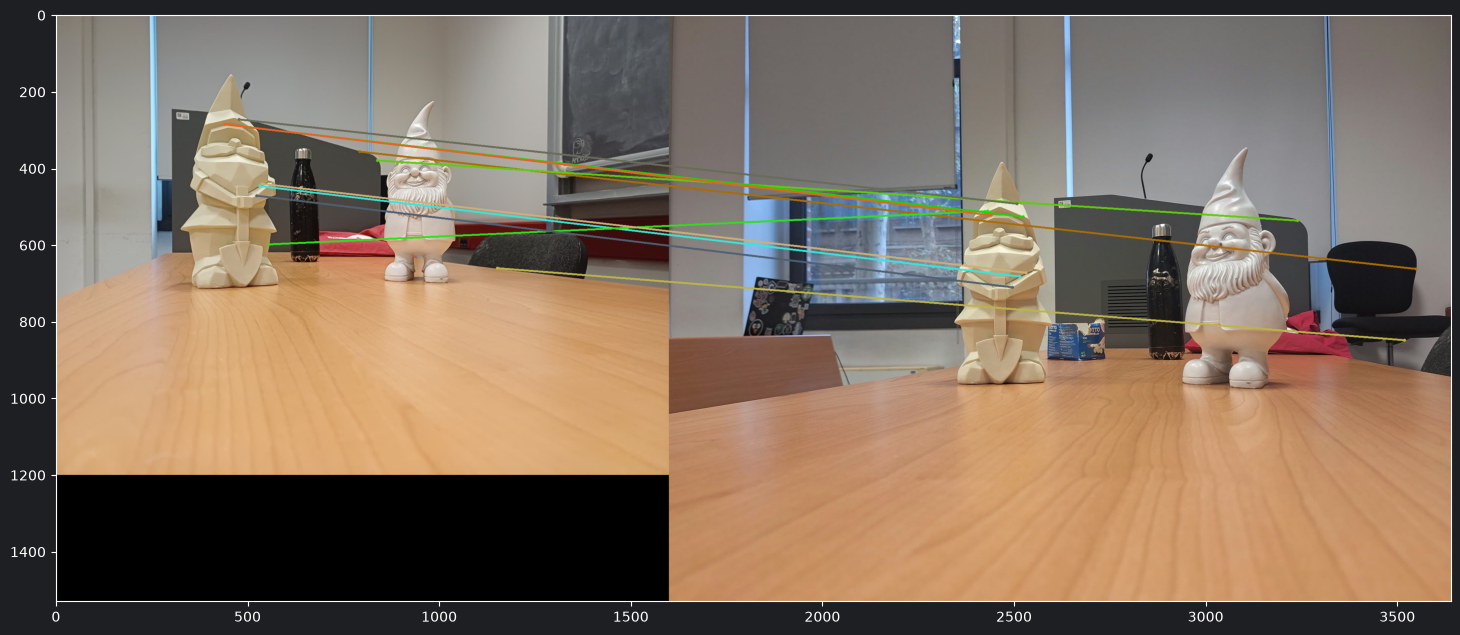

Pair 3: Found 529 total matches
fundamental_matrix:
[[-3.70468366e-06  6.39391889e-06 -2.31137247e-04]
 [-1.27577494e-06  5.51479038e-06 -1.27896318e-03]
 [ 3.89101908e-03 -8.62257250e-03  9.99954410e-01]]


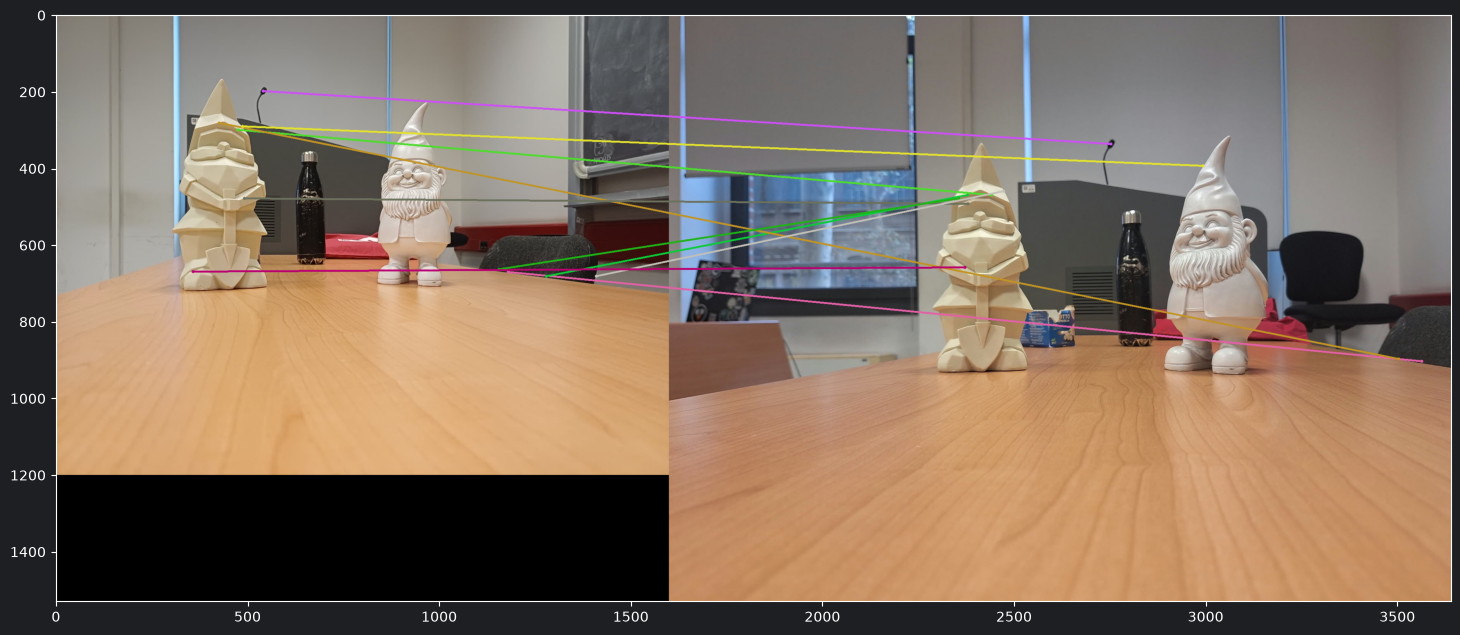

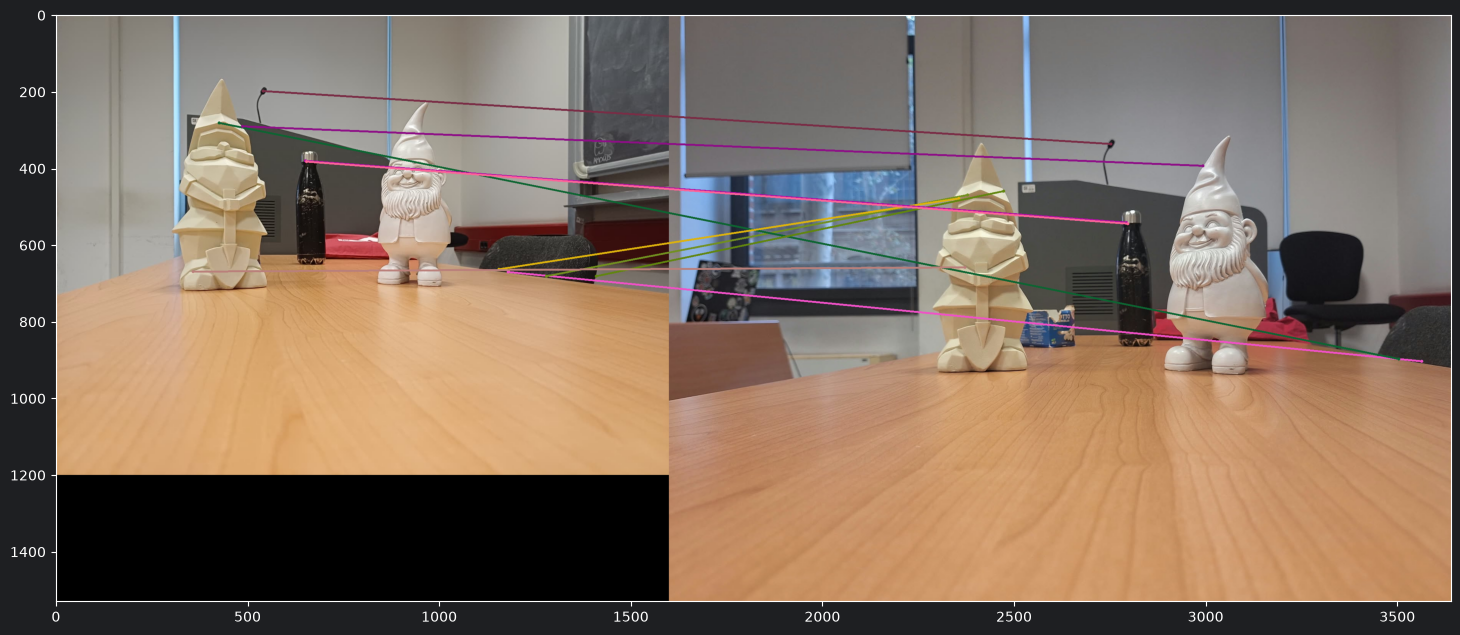

In [3]:
sift = cv2.SIFT_create()
fundamental_matrices = [] # To store F for each pair

for i in range(1, 4):
    prime = cv2.imread(f'stereo_camera/{i}_prime.jpeg')
    second = cv2.imread(f'stereo_camera/{i}_second.jpeg')

    prime_gray = cv2.cvtColor(prime, cv2.COLOR_BGR2GRAY)
    second_gray = cv2.cvtColor(second, cv2.COLOR_BGR2GRAY)

    prime_keypoints, prime_descriptors = sift.detectAndCompute(prime_gray, None)
    second_keypoints, second_descriptors = sift.detectAndCompute(second_gray, None)

    # Find the matches minimizing the Euclidean distance between descriptors
    bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=True)
    matched = bf.match(prime_descriptors, second_descriptors)

    # Sort the matches based on their distance
    matched = sorted(matched, key=lambda x: x.distance)

    # CONVERT MATCHES TO 2D VECTORS (NUMPY ARRAYS)
    # Extract coordinates corresponding to the match indices
    pts1 = np.float32([prime_keypoints[m.queryIdx].pt for m in matched])
    pts2 = np.float32([second_keypoints[m.trainIdx].pt for m in matched])

    # create matrix to apply svd
    M = []
    numPairs = 10
    for j in range(0, numPairs):
        pt1 = pts1[j]
        pt2 = pts2[j]
        u = pt1[0]
        v = pt1[1]
        x = pt2[0]
        y = pt2[1]

        M.append([u*x, x *v,x,u*y,v*y,y,u,v,1])
    M = np.array(M)
    # Perform SVD
    U, S, Vt = np.linalg.svd(M)
    # The solution is the last column of V (or the last row of Vt)
    F = Vt[-1].reshape(3, 3)
    fundamental_matrices.append(F)

    print(f"Pair {i}: Found {len(pts1)} total matches")
    print("fundamental_matrix:")
    print(F)
    # DRAW MATCHES
    # Draw only the top matches (or use inliers if preferred)
    matched_image = draw_thick_matches(prime, prime_keypoints, second, second_keypoints, matched[:numPairs])

    # Display the matched images
    plt.figure(figsize=(18, 9))
    plt.imshow(cv2.cvtColor(matched_image, cv2.COLOR_BGR2RGB))
    plt.show()

    # --- Automatically select clean matches coherent with F ---
    epsilon = 0.05
    coherent_matches = []

    for m in matched:
        p1 = np.array([prime_keypoints[m.queryIdx].pt[0], prime_keypoints[m.queryIdx].pt[1], 1.0])
        p2 = np.array([second_keypoints[m.trainIdx].pt[0], second_keypoints[m.trainIdx].pt[1], 1.0])

        # Epipolar constraint
        error = abs(p2.T @ F @ p1)
        if error < epsilon:
            coherent_matches.append(m)

    # --- Draw the coherent matches ---
    matched_image = draw_thick_matches(
        prime, prime_keypoints,
        second, second_keypoints,
        coherent_matches[:numPairs]
    )

    plt.figure(figsize=(18, 9))
    plt.imshow(cv2.cvtColor(matched_image, cv2.COLOR_BGR2RGB))
    plt.show()

    # rectification

    U, S, Vt = np.linalg.svd(F)  # calculate left epipole by SVD decomposition of the fundamental matrix
    e1 = Vt[-1].reshape(3,1)
    e2 = [-e1[1], e1[0], 0 ]
    e3 = e1 * e2;

    Rrect = [e1,e2,e3]



